# 05 — Insights de atracações | Porto de Santos

**Objetivo:** explorar e validar a base limpa de atracações (2021–2026), produzir indicadores diários, mensais e por perfil/tipo de viagem e exportar tabelas para o Power BI.

Este notebook **não substitui** `src/atracacoes/clean_atracacoes.py`: ele lê a saída do ETL. Os dados de 2026 são parciais. Não se infere impacto climático apenas por variação no número de atracações.

In [3]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# Localiza a raiz do projeto
ROOT = Path.cwd().resolve()

while ROOT.name != "porto-santos":
    if ROOT == ROOT.parent:
        raise FileNotFoundError(
            "Não foi possível localizar a pasta porto-santos."
        )
    ROOT = ROOT.parent

# Localiza o CSV limpo
ARQUIVO = (
    ROOT
    / "data"
    / "processed"
    / "atracacoes"
    / "atracacoes_limpo_2021_2026.csv"
)

# Pasta de destino dos insights
DESTINO = ROOT / "data" / "processed" / "atracacoes"
DESTINO.mkdir(parents=True, exist_ok=True)

# Verifica se o CSV existe
if not ARQUIVO.exists():
    raise FileNotFoundError(
        f"Arquivo não encontrado: {ARQUIVO}"
    )

# Carrega os dados
df = pd.read_csv(ARQUIVO, encoding="utf-8-sig")

print("Arquivo encontrado:", ARQUIVO)
print("Dimensões:", df.shape)

display(df.head())

Arquivo encontrado: C:\Users\Lenovo\Desktop\porto-santos\data\processed\atracacoes\atracacoes_limpo_2021_2026.csv
Dimensões: (31116, 11)


,QUANTIDADE_ATRACACAO,MERCADORIA,ANO,PERFIL_EMBARCACAO,NATUREZA_CARGA,MES,DESATRACACAO,ATRACACAO,NUMERO_VIAGEM,TIPO_VIAGEM,ANO_MES
0,1,CONTEINERES CHEIOS,2021,GRANELEIRO,CARGA CONTEINERIZADA,1,2021-01-03 00:00:00,2021-01-02 00:00:00,117669,LONGO CURSO,2021-01-01 00:00:00
1,1,OLEO COMBUSTIVEL,2021,PETROLEIRO,GRANEL LIQUIDO,1,2021-03-24 00:00:00,2021-01-14 00:00:00,117690,CABOTAGEM,2021-01-01 00:00:00
2,1,FERTILIZANTES,2021,GRANELEIRO,GRANEL SOLIDO,1,2021-01-11 00:00:00,2021-01-07 00:00:00,117698,LONGO CURSO,2021-01-01 00:00:00
3,1,CONTEINERES CHEIOS,2021,PORTA-CONTAINERS,CARGA CONTEINERIZADA,1,2021-01-02 00:00:00,2021-01-02 00:00:00,117714,LONGO CURSO,2021-01-01 00:00:00
4,1,FERTILIZANTES,2021,CARGUEIRO COMUM,GRANEL SOLIDO,1,2021-01-07 00:00:00,2021-01-04 00:00:00,117745,LONGO CURSO,2021-01-01 00:00:00


## 1. Carregamento e tipos
Padronizamos **somente os nomes das colunas no notebook**, sem modificar o CSV gerado pelo script de limpeza.

In [4]:
df = pd.read_csv(ARQUIVO, encoding="utf-8-sig", low_memory=False)
df.columns = df.columns.str.strip().str.lower()

obrigatorias = ["atracacao", "desatracacao", "ano", "mes", "perfil_embarcacao", "tipo_viagem"]
faltantes = [col for col in obrigatorias if col not in df.columns]
if faltantes:
    raise ValueError(f"Colunas obrigatórias ausentes: {faltantes}")

for col in ["atracacao", "desatracacao", "ano_mes"]:
    if col in df:
        df[col] = pd.to_datetime(df[col], errors="coerce", dayfirst=False)
for col in ["ano", "mes", "quantidade_atracacao", "numero_viagem", "duracao_dias_calendario"]:
    if col in df:
        df[col] = pd.to_numeric(df[col], errors="coerce")
for col in ["perfil_embarcacao", "tipo_viagem", "mercadoria", "natureza_carga"]:
    if col in df:
        df[col] = df[col].astype("string").str.strip().str.upper()

# Algumas versões do ETL não têm flags prontas.
if "requer_revisao" in df:
    df["requer_revisao"] = df["requer_revisao"].astype("string").str.lower().eq("true")
else:
    df["requer_revisao"] = False

df["data_atracacao"] = df["atracacao"].dt.normalize()
df["ano"] = df["atracacao"].dt.year.astype("Int64")
df["mes"] = df["atracacao"].dt.month.astype("Int64")
df["ano_mes"] = df["atracacao"].dt.to_period("M").dt.to_timestamp()
print(f"Registros: {len(df):,} | Colunas: {len(df.columns)}")
print("Período:", df["atracacao"].min(), "até", df["atracacao"].max())
display(df.head())

Registros: 31,116 | Colunas: 13
Período: 2021-01-01 00:00:00 até 2026-09-30 00:00:00


,quantidade_atracacao,mercadoria,ano,perfil_embarcacao,natureza_carga,mes,desatracacao,atracacao,numero_viagem,tipo_viagem,ano_mes,requer_revisao,data_atracacao
0,1,CONTEINERES CHEIOS,2021,GRANELEIRO,CARGA CONTEINERIZADA,1,2021-01-03,2021-01-02,117669,LONGO CURSO,2021-01-01,False,2021-01-02
1,1,OLEO COMBUSTIVEL,2021,PETROLEIRO,GRANEL LIQUIDO,1,2021-03-24,2021-01-14,117690,CABOTAGEM,2021-01-01,False,2021-01-14
2,1,FERTILIZANTES,2021,GRANELEIRO,GRANEL SOLIDO,1,2021-01-11,2021-01-07,117698,LONGO CURSO,2021-01-01,False,2021-01-07
3,1,CONTEINERES CHEIOS,2021,PORTA-CONTAINERS,CARGA CONTEINERIZADA,1,2021-01-02,2021-01-02,117714,LONGO CURSO,2021-01-01,False,2021-01-02
4,1,FERTILIZANTES,2021,CARGUEIRO COMUM,GRANEL SOLIDO,1,2021-01-07,2021-01-04,117745,LONGO CURSO,2021-01-01,False,2021-01-04


## 2. Validação da base limpa
Não confundimos *registros*, *viagens distintas* e a soma da coluna `quantidade_atracacao` (que só deve ser utilizada quando seu significado estiver documentado).

In [5]:
print("Linhas:", len(df))
print("Duplicatas exatas (após colunas derivadas):", int(df.duplicated().sum()))
print("Datas de atracação inválidas:", int(df["atracacao"].isna().sum()))
print("Datas de desatracação inválidas/ausentes:", int(df["desatracacao"].isna().sum()))
print("Desatracação anterior à atracação:", int((df["desatracacao"] < df["atracacao"]).sum()))
print("Registros marcados para revisão:", int(df["requer_revisao"].sum()))

qualidade = pd.DataFrame({
    "coluna": df.columns,
    "ausentes": df.isna().sum().values,
    "percentual_ausente": (df.isna().mean() * 100).round(2).values,
})
display(qualidade.sort_values("percentual_ausente", ascending=False))

Linhas: 31116
Duplicatas exatas (após colunas derivadas): 0
Datas de atracação inválidas: 0
Datas de desatracação inválidas/ausentes: 0
Desatracação anterior à atracação: 0
Registros marcados para revisão: 0


,coluna,ausentes,percentual_ausente
1,mercadoria,3,0.01
0,quantidade_atracacao,0,0.00
2,ano,0,0.00
3,perfil_embarcacao,0,0.00
4,natureza_carga,0,0.00
5,mes,0,0.00
6,desatracacao,0,0.00
7,atracacao,0,0.00
8,numero_viagem,0,0.00
9,tipo_viagem,0,0.00


## 3. Movimento anual
**Cuidado:** 2026 é parcial; não comparar seu total diretamente com anos completos.

,ano,registros,dias_com_atracacao,revisoes,viagens_distintas
0,2021,4837,365,0,4837
1,2022,5190,364,0,5190
2,2023,5478,365,0,5478
3,2024,5595,364,0,5595
4,2025,5773,365,0,5773
5,2026,4243,273,0,4243


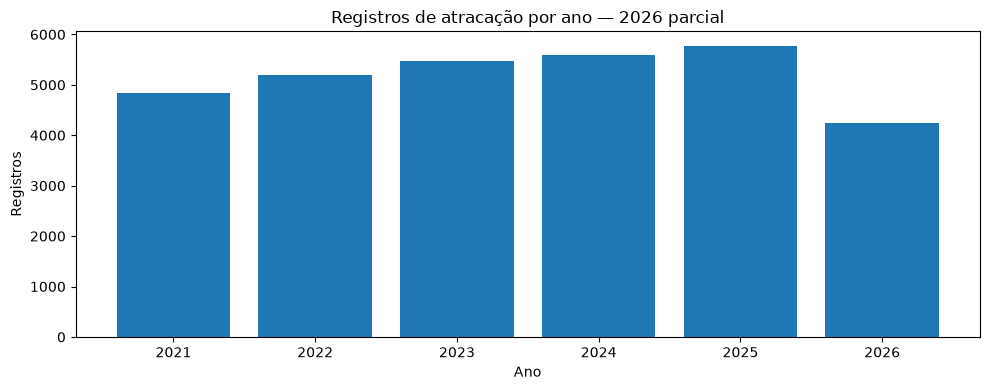

In [6]:
anual = (df.groupby("ano", dropna=False)
         .agg(registros=("atracacao", "size"),
              dias_com_atracacao=("data_atracacao", "nunique"),
              revisoes=("requer_revisao", "sum"))
         .reset_index())
if "numero_viagem" in df:
    anual = anual.merge(df.groupby("ano")["numero_viagem"].nunique().rename("viagens_distintas").reset_index(), on="ano", how="left")
display(anual)

plt.figure(figsize=(10, 4))
plt.bar(anual["ano"].astype(str), anual["registros"])
plt.title("Registros de atracação por ano — 2026 parcial")
plt.xlabel("Ano")
plt.ylabel("Registros")
plt.tight_layout()
plt.show()

## 4. Movimentação mensal e sazonalidade
A contagem de linhas é um indicador de registros de atracação, **não** de atrasos ou bloqueios.

,ano,mes,ano_mes,atracacoes_registradas,dias_com_atracacao,registros_para_revisao
0,2021,1,2021-01-01,338,31,0
1,2021,2,2021-02-01,381,28,0
2,2021,3,2021-03-01,444,31,0
3,2021,4,2021-04-01,424,30,0
4,2021,5,2021-05-01,432,31,0
5,2021,6,2021-06-01,423,30,0
6,2021,7,2021-07-01,397,31,0
7,2021,8,2021-08-01,393,31,0
8,2021,9,2021-09-01,394,30,0
9,2021,10,2021-10-01,392,31,0


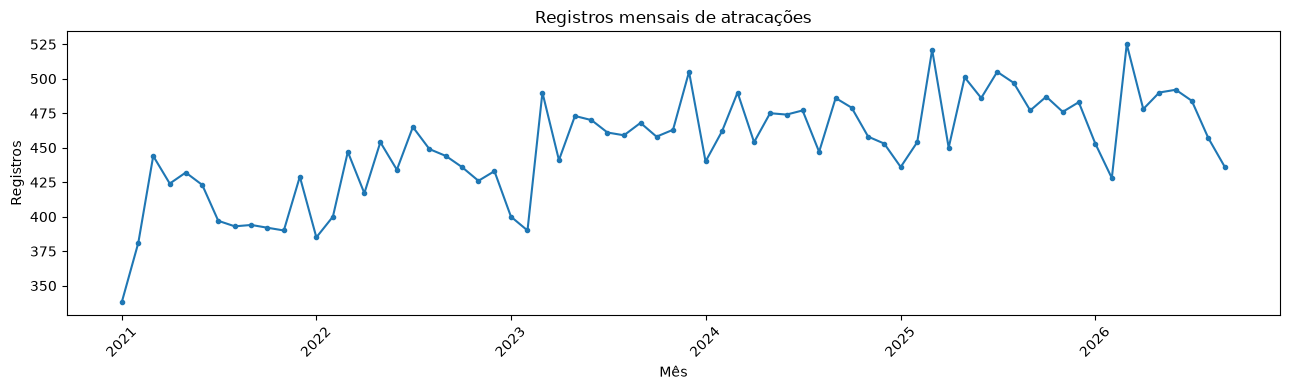

In [7]:
mensal = (df.dropna(subset=["ano_mes"])
          .groupby(["ano", "mes", "ano_mes"], as_index=False)
          .agg(atracacoes_registradas=("atracacao", "size"),
               dias_com_atracacao=("data_atracacao", "nunique"),
               registros_para_revisao=("requer_revisao", "sum")))
display(mensal.head(12))
plt.figure(figsize=(13, 4))
plt.plot(mensal["ano_mes"], mensal["atracacoes_registradas"], marker=".")
plt.title("Registros mensais de atracações")
plt.xlabel("Mês")
plt.ylabel("Registros")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

ano,2021,2022,2023,2024,2025,2026
mes,,,,,,
1,338.0,385.0,400.0,440.0,436.0,453.0
2,381.0,400.0,390.0,462.0,454.0,428.0
3,444.0,447.0,490.0,490.0,521.0,525.0
4,424.0,417.0,441.0,454.0,450.0,478.0
5,432.0,454.0,473.0,475.0,501.0,490.0
6,423.0,434.0,470.0,474.0,486.0,492.0
7,397.0,465.0,461.0,477.0,505.0,484.0
8,393.0,449.0,459.0,447.0,497.0,457.0
9,394.0,444.0,468.0,486.0,477.0,436.0


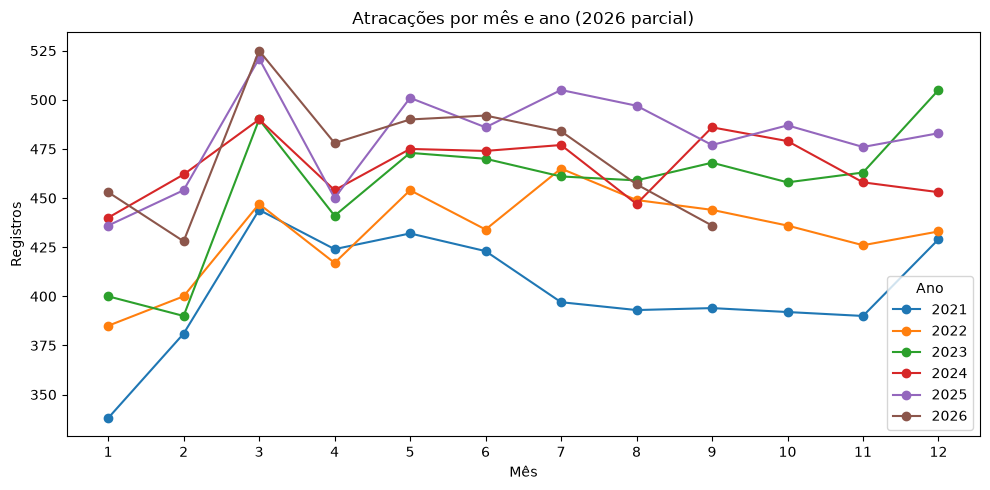

In [8]:
# Comparação mês a mês — útil para comparar períodos equivalentes.
matriz = mensal.pivot(index="mes", columns="ano", values="atracacoes_registradas")
display(matriz)
plt.figure(figsize=(10, 5))
for ano in matriz.columns:
    plt.plot(matriz.index, matriz[ano], marker="o", label=str(ano))
plt.title("Atracações por mês e ano (2026 parcial)")
plt.xlabel("Mês")
plt.ylabel("Registros")
plt.xticks(range(1, 13))
plt.legend(title="Ano")
plt.tight_layout()
plt.show()

## 5. Perfis de embarcação e tipos de viagem
Os rankings são contagens de registros. Se a mesma viagem aparecer mais de uma vez, a métrica não equivale a viagens únicas.

,perfil_embarcacao,registros
11,PORTA-CONTAINERS,11523
7,GRANELEIRO,10455
10,PETROLEIRO,3802
2,CARGUEIRO COMUM,1966
14,ROLL-ON/ROLL-OFF,1305
9,PASSAGEIRO,623
12,QUIMICO,594
16,TANQUE,327
4,EMBARCACAO DE APOIO,293
6,GAS LIQUEFEITO,86


,tipo_viagem,registros
1,LONGO CURSO,26163
0,CABOTAGEM,4953


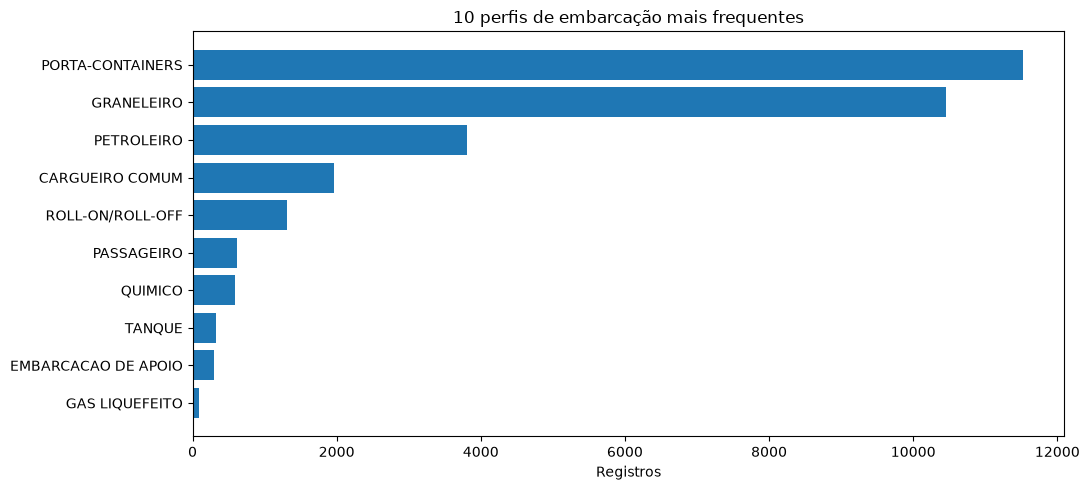

In [9]:
perfil = (df.groupby("perfil_embarcacao", dropna=False)
          .size().rename("registros").reset_index()
          .sort_values("registros", ascending=False))
tipo_viagem = (df.groupby("tipo_viagem", dropna=False)
               .size().rename("registros").reset_index()
               .sort_values("registros", ascending=False))
display(perfil.head(15))
display(tipo_viagem)
plt.figure(figsize=(11, 5))
top = perfil.head(10).sort_values("registros")
plt.barh(top["perfil_embarcacao"].fillna("NÃO INFORMADO"), top["registros"])
plt.title("10 perfis de embarcação mais frequentes")
plt.xlabel("Registros")
plt.tight_layout()
plt.show()

## 6. Movimentação diária — pronta para cruzar com meteorologia
O agrupamento por **dia** evita inferir horários exatos de chegada quando a origem registra apenas `00:00:00`. Não prova causalidade climática.

,data,atracacoes_registradas,registros_para_revisao,ano,mes
1330,2024-08-23,32,0,2024,8
1348,2024-09-10,32,0,2024,9
1311,2024-08-04,30,0,2024,8
1908,2026-03-24,29,0,2026,3
1093,2023-12-30,27,0,2023,12
1536,2025-03-17,27,0,2025,3
1305,2024-07-29,26,0,2024,7
532,2022-06-17,25,0,2022,6
581,2022-08-05,25,0,2022,8
1327,2024-08-20,25,0,2024,8


Dias com zero registros: 3


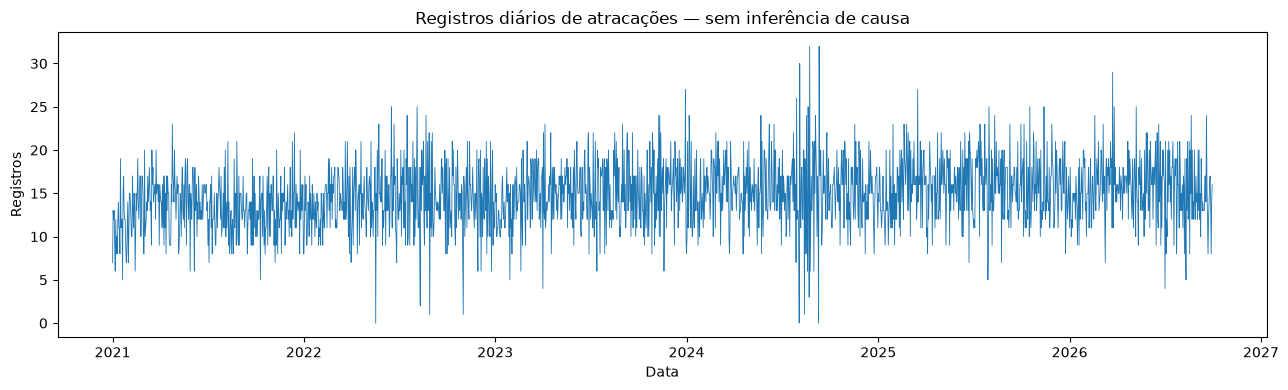

In [10]:
diario = (df.dropna(subset=["data_atracacao"])
          .groupby("data_atracacao", as_index=False)
          .agg(atracacoes_registradas=("atracacao", "size"),
               registros_para_revisao=("requer_revisao", "sum")))
# Inclui dias sem registros como zero atracações na base (não significa porto fechado).
intervalo = pd.date_range(diario["data_atracacao"].min(), diario["data_atracacao"].max(), freq="D")
diario = (diario.set_index("data_atracacao")
          .reindex(intervalo, fill_value=0)
          .rename_axis("data")
          .reset_index())
diario["ano"] = diario["data"].dt.year
diario["mes"] = diario["data"].dt.month

display(diario.nlargest(10, "atracacoes_registradas"))
print("Dias com zero registros:", int(diario["atracacoes_registradas"].eq(0).sum()))
plt.figure(figsize=(13, 4))
plt.plot(diario["data"], diario["atracacoes_registradas"], linewidth=0.6)
plt.title("Registros diários de atracações — sem inferência de causa")
plt.xlabel("Data")
plt.ylabel("Registros")
plt.tight_layout()
plt.show()

## 7. Duração observada entre datas
As datas frequentemente não têm horário confiável; portanto a diferença é **em dias de calendário**, não em horas reais de ocupação. Valores acima de 30 dias ou negativos devem ser revisados, não apagados automaticamente.

Durações válidas na faixa exploratória 0–30 dias: 31001
Fora da faixa ou ausentes: 115


,dias
count,31001.000000
mean,2.888455
std,3.297782
min,0.000000
25%,1.000000
50%,2.000000
75%,3.000000
90%,6.000000
95%,9.000000
max,30.000000


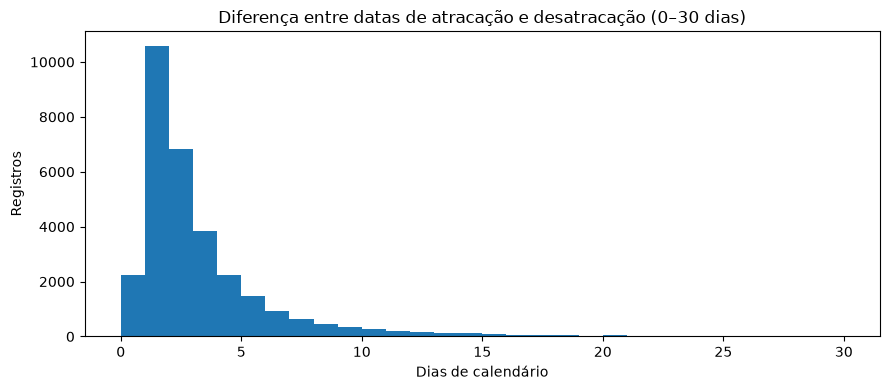

In [11]:
df["duracao_dias_observados"] = (df["desatracacao"] - df["atracacao"]).dt.total_seconds() / 86400
validas = df["duracao_dias_observados"].between(0, 30, inclusive="both")
duracoes = df.loc[validas, "duracao_dias_observados"]
print("Durações válidas na faixa exploratória 0–30 dias:", len(duracoes))
print("Fora da faixa ou ausentes:", int((~validas).sum()))
display(duracoes.describe(percentiles=[.25, .5, .75, .9, .95]).to_frame("dias"))
plt.figure(figsize=(9, 4))
plt.hist(duracoes, bins=30)
plt.title("Diferença entre datas de atracação e desatracação (0–30 dias)")
plt.xlabel("Dias de calendário")
plt.ylabel("Registros")
plt.tight_layout()
plt.show()

## 8. Principais insights calculados automaticamente
As frases abaixo são geradas **a partir dos valores efetivos do CSV**, sem preencher resultados no texto antecipadamente.

In [12]:
ano_completo = anual.loc[anual["ano"].between(2021, 2025)].copy()
if not ano_completo.empty:
    maior_ano = ano_completo.loc[ano_completo["registros"].idxmax()]
    print(f"• Maior total anual entre 2021 e 2025: {int(maior_ano['ano'])} ({int(maior_ano['registros']):,} registros).")
if 2021 in anual["ano"].values and 2025 in anual["ano"].values:
    a = int(anual.loc[anual["ano"].eq(2021), "registros"].iloc[0])
    z = int(anual.loc[anual["ano"].eq(2025), "registros"].iloc[0])
    if a:
        print(f"• Variação de registros de 2021 a 2025: {(z / a - 1) * 100:+.2f}%.")
if not perfil.empty:
    print(f"• Perfil mais frequente: {perfil.iloc[0]['perfil_embarcacao']} ({int(perfil.iloc[0]['registros']):,} registros).")
if not tipo_viagem.empty:
    print(f"• Tipo de viagem mais frequente: {tipo_viagem.iloc[0]['tipo_viagem']} ({int(tipo_viagem.iloc[0]['registros']):,} registros).")
print(f"• Registros sinalizados para revisão: {int(df['requer_revisao'].sum()):,}.")
print("• Esses números descrevem atracações registradas; não demonstram impacto do clima por si só.")

• Maior total anual entre 2021 e 2025: 2025 (5,773 registros).
• Variação de registros de 2021 a 2025: +19.35%.
• Perfil mais frequente: PORTA-CONTAINERS (11,523 registros).
• Tipo de viagem mais frequente: LONGO CURSO (26,163 registros).
• Registros sinalizados para revisão: 0.
• Esses números descrevem atracações registradas; não demonstram impacto do clima por si só.


## 9. Exportações para o Power BI
O CSV limpo é a fonte detalhada. As tabelas abaixo são auxiliares e **não devem ser somadas à base detalhada** no mesmo visual, pois possuem granularidades diferentes.

In [13]:
saidas = {
    "atracacoes_resumo_anual_2021_2026.csv": anual,
    "atracacoes_resumo_mensal_2021_2026.csv": mensal,
    "atracacoes_resumo_diario_2021_2026.csv": diario,
    "atracacoes_perfil_embarcacao_2021_2026.csv": perfil,
    "atracacoes_tipo_viagem_2021_2026.csv": tipo_viagem,
    "atracacoes_qualidade_colunas_2021_2026.csv": qualidade,
}
for nome, tabela in saidas.items():
    caminho = DESTINO / nome
    tabela.to_csv(caminho, index=False, encoding="utf-8-sig", date_format="%Y-%m-%d")
    print(f"✓ {caminho} — {len(tabela):,} linhas")
print("\nFonte detalhada do Power BI:", ARQUIVO)

✓ C:\Users\Lenovo\Desktop\porto-santos\data\processed\atracacoes\atracacoes_resumo_anual_2021_2026.csv — 6 linhas
✓ C:\Users\Lenovo\Desktop\porto-santos\data\processed\atracacoes\atracacoes_resumo_mensal_2021_2026.csv — 69 linhas
✓ C:\Users\Lenovo\Desktop\porto-santos\data\processed\atracacoes\atracacoes_resumo_diario_2021_2026.csv — 2,099 linhas
✓ C:\Users\Lenovo\Desktop\porto-santos\data\processed\atracacoes\atracacoes_perfil_embarcacao_2021_2026.csv — 17 linhas
✓ C:\Users\Lenovo\Desktop\porto-santos\data\processed\atracacoes\atracacoes_tipo_viagem_2021_2026.csv — 2 linhas
✓ C:\Users\Lenovo\Desktop\porto-santos\data\processed\atracacoes\atracacoes_qualidade_colunas_2021_2026.csv — 13 linhas

Fonte detalhada do Power BI: C:\Users\Lenovo\Desktop\porto-santos\data\processed\atracacoes\atracacoes_limpo_2021_2026.csv
